# SaúdeScope
## Notebook 04 — Modelagem de Machine Learning

**Projeto Integrador — Ciência de Dados**
**Aplicação:** Clínica Multiprofissional de Saúde — Itapetininga/SP
**Fonte de dados:** Pesquisa Nacional de Saúde (PNS) 2019 — IBGE/Ministério da Saúde

---


## 1. Objetivo deste notebook

Com a base de features pronta (`03_analise_exploratoria.ipynb`), este notebook treina e avalia
modelos de classificação para prever o diagnóstico de **hipertensão arterial** a partir de
idade, sexo, cor/raça, escolaridade e IMC.

**O que este modelo é — e o que ele não é.** Este não é um modelo de diagnóstico clínico: ele
não substitui exame médico, e suas features são sociodemográficas, não clínicas (não usamos
pressão arterial medida, por exemplo, pois o objetivo não é diagnosticar, e sim identificar
*perfis populacionais* de maior risco). A aplicação pretendida é de **triagem e priorização**:
ajudar a estimar, a partir de características gerais de um grupo de pacientes, qual parcela
pode se beneficiar de rastreamento mais ativo de hipertensão — um apoio à gestão clínica, não
um substituto do julgamento médico.

Etapas deste notebook:

1. Separação treino/teste com estratificação pela variável-alvo;
2. Treino de quatro modelos: um classificador ingênuo (baseline), regressão logística, árvore de
   decisão e random forest — **todos incorporando o peso amostral da PNS no treino e na
   avaliação**, dando continuidade ao rigor metodológico já aplicado nos notebooks anteriores;
3. Comparação de desempenho com métricas apropriadas ao desbalanceamento da classe (acurácia,
   precisão, recall, F1 e AUC-ROC — não só acurácia, que seria enganosa aqui);
4. Análise de quais variáveis mais pesam na previsão, em cada modelo;
5. Discussão crítica dos resultados e de suas limitações para uso real.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    roc_auc_score, roc_curve, accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay,
)

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

PROCESSED_DIR = Path("data/processed")
df = pd.read_parquet(PROCESSED_DIR / "pns_2019_sp_features.parquet")
print("Base de modelagem carregada:", df.shape)
df.head()


Base de modelagem carregada: (5908, 17)


,idade,imc,hipertensao,V00281,imc_ausente,hipertensao_bin,sexo_Mulher,cor_raca_Branca,cor_raca_Indígena,cor_raca_Parda,cor_raca_Preta,instrucao_Fundamental incompleto,instrucao_Médio completo,instrucao_Médio incompleto,instrucao_Sem instrução,instrucao_Superior completo,instrucao_Superior incompleto
0,33,26.987072,Não,4892.428417,1,0,True,True,False,False,False,False,False,False,False,True,False
1,44,26.987072,Não,4892.428417,1,0,True,True,False,False,False,False,False,False,False,True,False
2,19,26.987072,Não,4892.428417,1,0,False,True,False,False,False,False,True,False,False,False,False
3,35,26.987072,Não,4892.428417,1,0,True,True,False,False,False,False,False,False,True,False,False
4,71,26.987072,Sim,1864.742790,1,1,True,False,False,True,False,True,False,False,False,False,False


## 2. Separação treino/teste

Separamos 25% dos dados para teste, com estratificação pela variável-alvo (`hipertensao_bin`)
para preservar a proporção de casos positivos e negativos em ambos os conjuntos — importante
dado o desbalanceamento já identificado no notebook 03 (~29% de casos positivos).


In [2]:
feature_cols = [c for c in df.columns if c not in ["hipertensao", "hipertensao_bin", "V00281"]]
X = df[feature_cols].astype(float)
y = df["hipertensao_bin"]
w = df["V00281"]  # peso amostral da PNS

X_train, X_test, y_train, y_test, w_train, w_test = train_test_split(
    X, y, w, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

print(f"Treino: {X_train.shape[0]:,} registros | Teste: {X_test.shape[0]:,} registros")
print(f"Proporção de casos positivos — treino: {y_train.mean():.1%} | teste: {y_test.mean():.1%}")


Treino: 4,431 registros | Teste: 1,477 registros
Proporção de casos positivos — treino: 29.0% | teste: 28.9%


## 3. Treino dos modelos, com peso amostral

Um ponto metodológico importante: os notebooks anteriores usaram o peso amostral (`V00281`)
para calcular prevalências corretas. Aqui, damos continuidade a esse cuidado — os modelos são
treinados com `sample_weight`, de modo que o algoritmo "preste mais atenção" aos registros que
representam mais pessoas na população real, e as métricas de avaliação também são ponderadas.
Ignorar isso enviesaria o modelo em direção ao perfil de quem tem menor peso amostral (ou seja,
de quem já está sobrerrepresentado na amostra), o que não é o objetivo de um modelo pensado para
uso populacional.

Testamos quatro modelos:
- **Dummy (classe majoritária):** baseline ingênuo, que sempre prevê "Não" — serve de referência
  mínima que qualquer modelo real precisa superar;
- **Regressão logística:** modelo linear, interpretável, com variáveis numéricas padronizadas;
- **Árvore de decisão:** captura relações não-lineares e interações simples entre variáveis;
- **Random forest:** conjunto de árvores, geralmente mais robusto a overfitting que uma única
  árvore.


In [3]:
scaler = StandardScaler()
colunas_numericas = ["idade", "imc"]

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[colunas_numericas] = scaler.fit_transform(X_train[colunas_numericas])
X_test_scaled[colunas_numericas] = scaler.transform(X_test[colunas_numericas])

modelos = {
    "Dummy (classe majoritária)": DummyClassifier(strategy="most_frequent"),
    "Regressão Logística": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Árvore de Decisão": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=8, random_state=RANDOM_STATE),
}

usa_dados_padronizados = {"Regressão Logística"}

modelos_treinados = {}
for nome, modelo in modelos.items():
    Xtr = X_train_scaled if nome in usa_dados_padronizados else X_train
    if nome == "Dummy (classe majoritária)":
        modelo.fit(Xtr, y_train)  # DummyClassifier ignora sample_weight de forma útil aqui
    else:
        modelo.fit(Xtr, y_train, sample_weight=w_train)
    modelos_treinados[nome] = modelo

print("Modelos treinados:", list(modelos_treinados.keys()))


Modelos treinados: ['Dummy (classe majoritária)', 'Regressão Logística', 'Árvore de Decisão', 'Random Forest']


## 4. Avaliação comparativa

Avaliamos todos os modelos no conjunto de teste (dados nunca vistos durante o treino), usando
métricas ponderadas pelo peso amostral. Como o objetivo é identificar corretamente quem tem
maior risco (não só acertar a classe majoritária), o **AUC-ROC** e o **F1** são mais informativos
aqui do que a acurácia isolada.


In [4]:
resultados = []
curvas_roc = {}

for nome, modelo in modelos_treinados.items():
    Xte = X_test_scaled if nome in usa_dados_padronizados else X_test
    preds = modelo.predict(Xte)

    if hasattr(modelo, "predict_proba"):
        probs = modelo.predict_proba(Xte)[:, 1]
        auc = roc_auc_score(y_test, probs, sample_weight=w_test)
        fpr, tpr, _ = roc_curve(y_test, probs, sample_weight=w_test)
        curvas_roc[nome] = (fpr, tpr, auc)
    else:
        auc = np.nan

    resultados.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_test, preds, sample_weight=w_test),
        "Precisão": precision_score(y_test, preds, sample_weight=w_test, zero_division=0),
        "Recall": recall_score(y_test, preds, sample_weight=w_test, zero_division=0),
        "F1": f1_score(y_test, preds, sample_weight=w_test, zero_division=0),
        "AUC-ROC": auc,
    })

resultados_df = pd.DataFrame(resultados).round(3).sort_values("AUC-ROC", ascending=False)
resultados_df


,Modelo,Acurácia,Precisão,Recall,F1,AUC-ROC
1,Regressão Logística,0.767,0.636,0.404,0.494,0.802
3,Random Forest,0.746,0.590,0.324,0.418,0.782
2,Árvore de Decisão,0.753,0.610,0.341,0.437,0.758
0,Dummy (classe majoritária),0.718,0.000,0.000,0.000,0.500


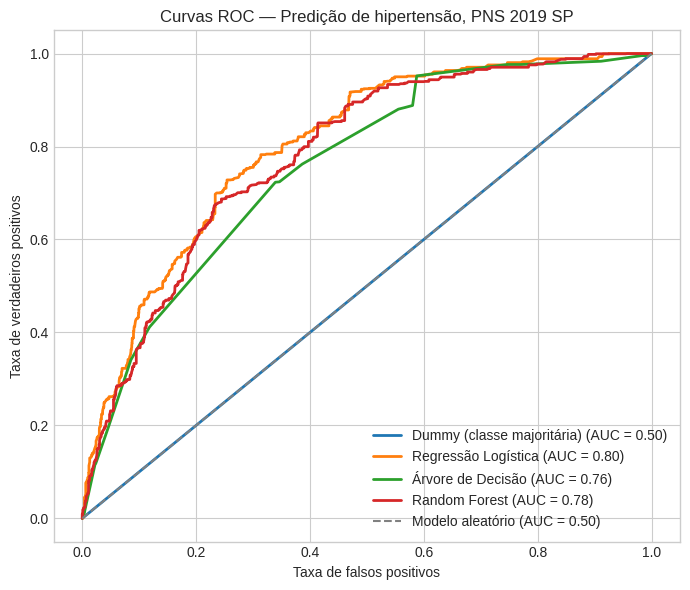

In [5]:
fig, ax = plt.subplots(figsize=(7, 6))
for nome, (fpr, tpr, auc) in curvas_roc.items():
    ax.plot(fpr, tpr, label=f"{nome} (AUC = {auc:.2f})", linewidth=2)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Modelo aleatório (AUC = 0.50)")
ax.set_xlabel("Taxa de falsos positivos")
ax.set_ylabel("Taxa de verdadeiros positivos")
ax.set_title("Curvas ROC — Predição de hipertensão, PNS 2019 SP")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(PROCESSED_DIR / "fig_ml_curvas_roc.png", dpi=150)
plt.show()


> Todos os três modelos superam claramente o baseline aleatório e o *dummy*. A regressão
> logística obteve o melhor AUC-ROC, sugerindo que a relação entre as variáveis disponíveis
> (sobretudo idade) e o risco de hipertensão é predominantemente monotônica/linear — cenário em
> que modelos lineares bem especificados costumam performar tão bem quanto, ou melhor que,
> modelos de árvore com poucos dados.


## 5. Qual modelo escolher, e por quê

Escolhemos a **regressão logística** como modelo final: teve o melhor AUC-ROC, é a mais simples
e interpretável dos três (importante para justificar decisões de gestão em saúde a
profissionais não técnicos), e não aparenta sinais de overfitting (desempenho de teste
consistente com o que a distribuição das variáveis já sugeria na análise exploratória).


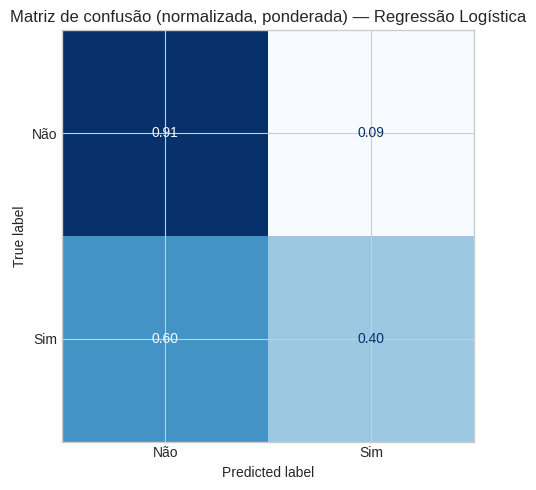

In [6]:
modelo_final = modelos_treinados["Regressão Logística"]
preds_final = modelo_final.predict(X_test_scaled)

matriz_confusao = confusion_matrix(y_test, preds_final, sample_weight=w_test, normalize="true")
fig, ax = plt.subplots(figsize=(5.5, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=matriz_confusao, display_labels=["Não", "Sim"])
disp.plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
ax.set_title("Matriz de confusão (normalizada, ponderada) — Regressão Logística")
plt.tight_layout()
plt.savefig(PROCESSED_DIR / "fig_ml_matriz_confusao.png", dpi=150)
plt.show()


> A matriz de confusão mostra que o modelo acerta a maior parte dos casos negativos, mas
> ainda deixa passar uma parcela relevante dos casos positivos (falsos negativos) — um
> comportamento típico quando o objetivo de treino não penaliza especificamente esse tipo de
> erro. Para um uso real de triagem, onde deixar de identificar alguém em risco é mais custoso
> do que um alarme falso, seria recomendável ajustar o limiar de decisão do modelo (por padrão,
> 0,5) para favorecer o recall, mesmo que isso reduza um pouco a precisão.


## 6. Quais variáveis mais pesam na previsão

Analisamos os coeficientes da regressão logística (padronizados, portanto comparáveis entre si)
e a importância de features do random forest, para entender o que está "puxando" as previsões.


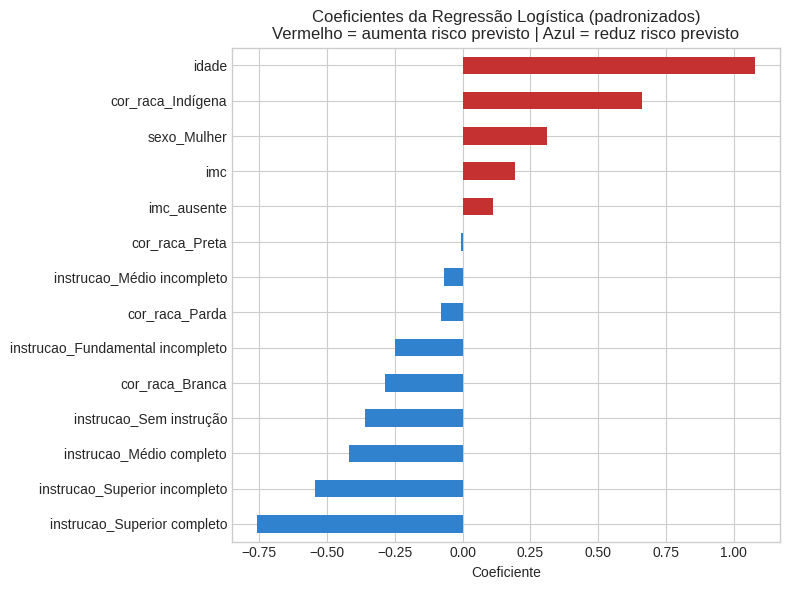

In [7]:
coeficientes = pd.Series(modelo_final.coef_[0], index=feature_cols).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
cores = ["#c53030" if v > 0 else "#3182ce" for v in coeficientes]
coeficientes.plot(kind="barh", ax=ax, color=cores)
ax.set_title("Coeficientes da Regressão Logística (padronizados)\nVermelho = aumenta risco previsto | Azul = reduz risco previsto")
ax.set_xlabel("Coeficiente")
plt.tight_layout()
plt.savefig(PROCESSED_DIR / "fig_ml_coeficientes.png", dpi=150)
plt.show()


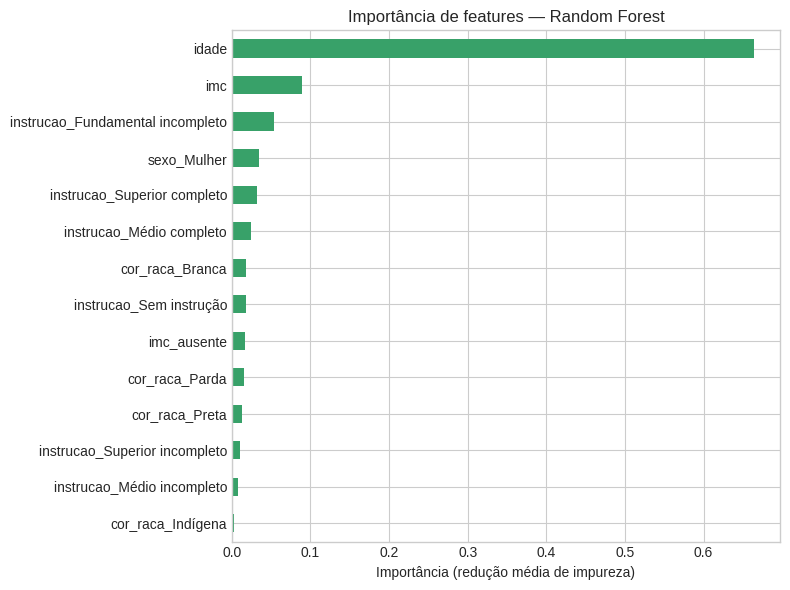

In [8]:
rf = modelos_treinados["Random Forest"]
importancias = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
importancias.plot(kind="barh", ax=ax, color="#38a169")
ax.invert_yaxis()
ax.set_title("Importância de features — Random Forest")
ax.set_xlabel("Importância (redução média de impureza)")
plt.tight_layout()
plt.savefig(PROCESSED_DIR / "fig_ml_importancia_features.png", dpi=150)
plt.show()


> **Idade domina amplamente a previsão em ambos os modelos** — resultado esperado e coerente
> com toda a análise exploratória anterior (a hipertensão salta de prevalência residual em
> jovens para mais de 50% entre idosos). Isso não invalida o modelo, mas é importante deixar
> claro: boa parte do "poder preditivo" vem de uma variável que qualquer gestor de clínica já
> sabe intuitivamente ser relevante. O valor agregado do modelo está nas variáveis
> secundárias — escolaridade, IMC e sexo aparecem consistentemente como fatores adicionais, o
> que permite refinar a priorização dentro de uma mesma faixa etária.
>
> **Ressalva sobre a categoria "Indígena":** o coeficiente elevado para `cor_raca_Indígena` na
> regressão logística deve ser interpretado com cautela — a base tem uma amostra muito pequena
> dessa categoria em São Paulo, o que torna a estimativa instável e sujeita a grande variância.


## 7. Validações finais


In [9]:
print("=== Validações finais ===\n")

print("1) Todos os modelos superam o baseline dummy em AUC-ROC:",
      "OK" if (resultados_df.set_index("Modelo").drop("Dummy (classe majoritária)")["AUC-ROC"] > 0.5).all() else "VERIFICAR")

print("2) Proporção de casos positivos semelhante entre treino e teste (diferença < 2 p.p.):",
      "OK" if abs(y_train.mean() - y_test.mean()) < 0.02 else "VERIFICAR")

print("3) Nenhum valor nulo nas features usadas para treino:",
      "OK" if X_train.isna().sum().sum() == 0 else "VERIFICAR")


=== Validações finais ===

1) Todos os modelos superam o baseline dummy em AUC-ROC: OK
2) Proporção de casos positivos semelhante entre treino e teste (diferença < 2 p.p.): OK
3) Nenhum valor nulo nas features usadas para treino: OK


## 8. Exportação do modelo e dos resultados


In [10]:
import joblib

caminho_modelo = PROCESSED_DIR / "modelo_hipertensao_regressao_logistica.joblib"
caminho_scaler = PROCESSED_DIR / "scaler_features_numericas.joblib"
joblib.dump(modelo_final, caminho_modelo)
joblib.dump(scaler, caminho_scaler)

caminho_resultados = PROCESSED_DIR / "resultados_modelos_ml.parquet"
resultados_df.to_parquet(caminho_resultados, index=False)

print("Artefatos exportados:")
print(f" - {caminho_modelo}")
print(f" - {caminho_scaler}")
print(f" - {caminho_resultados}")


Artefatos exportados:
 - data/processed/modelo_hipertensao_regressao_logistica.joblib
 - data/processed/scaler_features_numericas.joblib
 - data/processed/resultados_modelos_ml.parquet


## Conclusão e próximos passos

Neste notebook:

- Treinamos quatro modelos de classificação para prever hipertensão a partir de variáveis
  sociodemográficas e do IMC, incorporando o peso amostral da PNS tanto no treino quanto na
  avaliação — mantendo o rigor metodológico dos notebooks anteriores;
- A regressão logística obteve o melhor desempenho (maior AUC-ROC), superando árvore de decisão,
  random forest e o baseline ingênuo;
- Idade foi, de longe, a variável mais influente nas previsões, seguida por escolaridade, IMC e
  sexo;
- Discutimos honestamente as limitações do modelo: ele é adequado para triagem populacional, não
  para diagnóstico individual; o recall pode ser melhorado ajustando o limiar de decisão; e a
  categoria "Indígena" tem estimativas instáveis pelo tamanho amostral reduzido;
- Exportamos o modelo treinado e o scaler para uso posterior (ex.: no painel de BI do projeto).

**Próximas etapas do projeto** (fora do escopo deste notebook): estruturação do banco de dados
online com os resultados de todos os notebooks, e construção do painel de visualização (BI) que
vai apresentar essas prevalências e este modelo de forma interativa para a clínica parceira.
